Choose a sample to run. `sample_id` can be one of:
- mouse_vas_deferens1
- mouse_vas_deferens2
- mouse_femoral_artery
- mouse_bladder
- mouse_trachea
- human_cornea
- insect_leg

In [11]:
max_angle = 18
interval = 6
n_bscans = int(max_angle/interval)*2+1
anglename = str(max_angle) + '-' + str(interval) + '-' + str(max_angle)

# sample_id = 'mouse_vas_deferens1'  # a string that denotes which data to run
sample_id = 'phantom'  # a string that denotes which data to run

data_directory = 'c:/Users/DEL-AIProjects/Documents/GitHub/limited_angle_ocrt_local_saves/Datasets/' + anglename + '/'  # where is the OCRT input data located?
save_directory = 'c:/Users/DEL-AIProjects/Documents/GitHub/limited_angle_ocrt_local_saves/saved_models_and_variables/' + anglename + '/'  # where to save the tf graph after optimization

# Registration of multiangle B-scans and synthesis of refractive index map
The registration metric is optimized with respect to the deformation model, which in this case is ray propagation through a spatially inhomogeneous refractive index map.

In [12]:
from __future__ import print_function, division
import OCRT
import importlib
importlib.reload(OCRT)
from OCRT import OCRT2D
import numpy as np

import tensorflow as tf
tf.compat.v1.disable_eager_execution()
import matplotlib.pyplot as plt
import numpy as np
from time import time
%matplotlib inline

a = OCRT2D(sample_id=sample_id,save_directory=save_directory)

In [ ]:
# adjust some parameters, depending on the sample:
if sample_id in ['mouse_bladder', 'mouse_femoral_artery', 'mouse_trachea', 'mouse_vas_deferens1']:
    num_iter = 200
elif sample_id in ['mouse_vas_deferens2']:
    num_iter = 300
elif sample_id in ['insect_leg']:
    num_iter = 500
elif sample_id in ['human_cornea']:
    num_iter = 500
    # this sample is more difficult to register, so use a multiresolution approach:
    a.use_multires = True
    a.size_factor_ = 1  # the final size_factor_ is 8
    a.switch_iter = 250
elif sample_id in ['phantom']:
    num_iter = 50
else:
    raise Exception('invalid sample_id: ' + sample_id)
    
# two tube sizes were used (same inner diameter, but different outer diameter):
if sample_id in ['mouse_vas_deferens1', 'mouse_vas_deferens2', 'mouse_trachea']:
    a.tube_diameter = 1.066  # in mm
elif sample_id in ['phantom']:
    a.tube_diameter = 0
    a.tube_present = False
    a.knownRI = True
    a.use_parametric_optimization = False
    a.n_back = 1.35 
else:
    a.tube_diameter = 1.108516

In [14]:
a.load_data_and_resolve_constants(data_directory=data_directory, max_angle = max_angle, angle_step = interval)
a.build_graph()

data loaded: 1.8832988739013672 sec


c:\Users\DEL-AIProjects\.conda\envs\ocrt\lib\site-packages\tensorflow\python\client\session.py:1770: UserWarning: An interactive session is already active. This can cause out-of-memory errors in some cases. You must explicitly call `InteractiveSession.close()` to release resources held by the other session(s).
  warnings.warn('An interactive session is already active. This can '


graph built: 12.383703231811523 sec


0 [1.2642717, 0.0, 0.0, 0.0005770487] 77.70890283584595
0


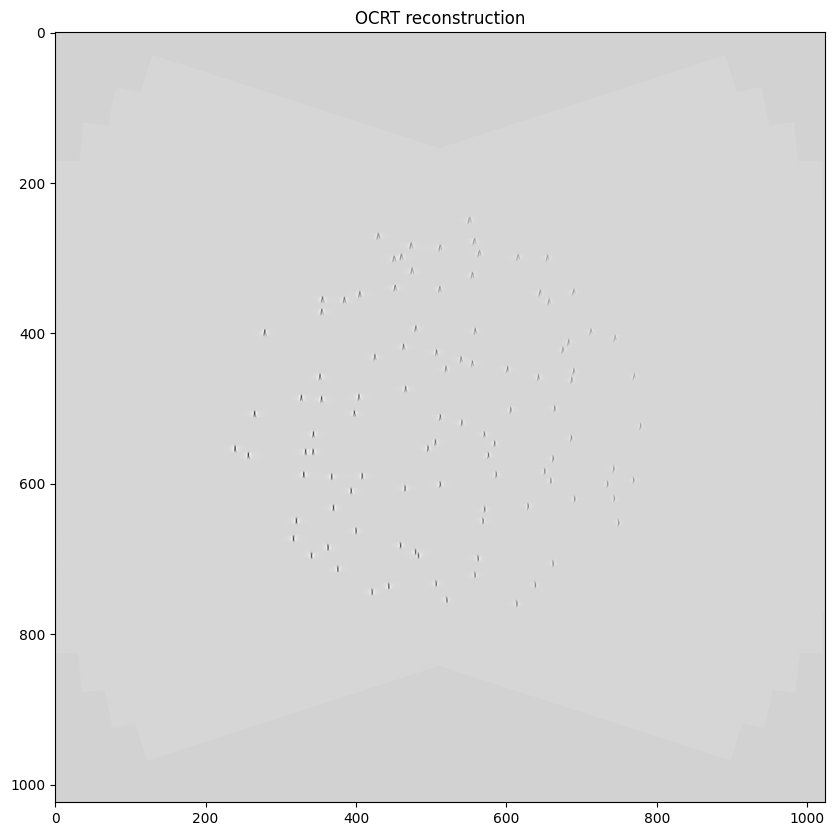

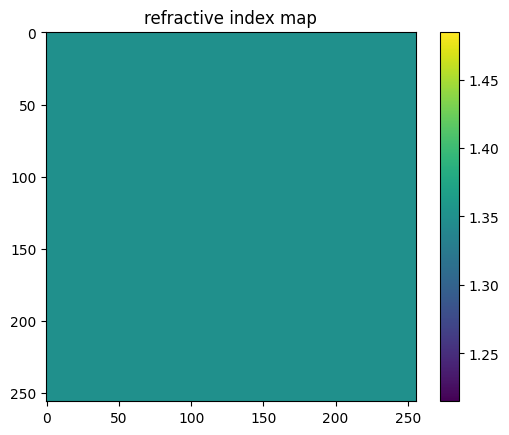

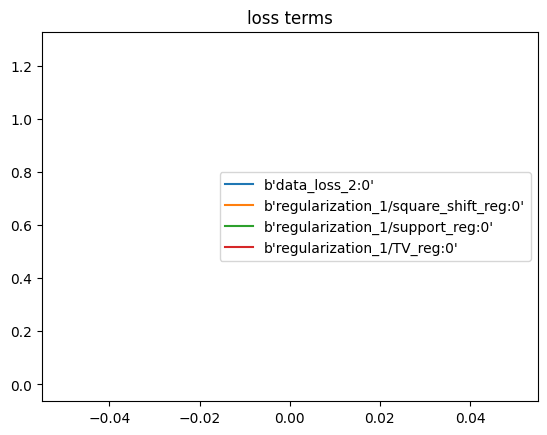

1 [1.2577131, 3.4985962e-05, 0.0, 0.0005770487] 69.34837770462036
1
2 [1.2504226, 9.379827e-06, 0.0, 0.0005770487] 83.54407572746277
2
3 [1.2439101, 5.3478234e-06, 0.0, 0.0005770487] 83.30043506622314
3
4 [1.2376223, 1.439772e-05, 0.0, 0.0005770487] 84.41072106361389
4
5 [1.2316265, 2.3078082e-05, 0.0, 0.0005770487] 89.85054159164429
5
6 [1.2259098, 2.7377475e-05, 0.0, 0.0005770487] 91.1876494884491
6
7 [1.2205143, 3.099742e-05, 0.0, 0.0005770487] 90.18655514717102
7


In [ ]:
# run through optimization loop:
losses = list()
feed_dict = a.get_feed_dict()
for i in range(num_iter + 1):
    
    # if using multires, change the pixel resolution of the reconstruction
    if i == a.switch_iter and a.use_multires: 
        feed_dict[a.size_factor] = a.final_size_factor
    
    start = time()
    loss_i, _ = a.sess.run([a.loss_terms, a.train_op], feed_dict=feed_dict)
    losses.append(loss_i)
    print(i, loss_i, time()-start)
    # loss_i is a list of all the contributors to the scalar loss;
    # (see a.loss_terms or a.loss_term_names for names of the regularization terms)
    print(i)
    # monitor results periodically:
    if i % 10 == 0:
        recon_i = a.sess.run(a.recon, feed_dict=feed_dict)
        recon_i = recon_i.sum(2)  # only once slice along y contains nonzero values, because we are optimizing 2D
        plt.figure(figsize=(10, 10))
        plt.imshow(recon_i, cmap='gray_r')
        plt.title('OCRT reconstruction')
        plt.show()
        
        RI = a.sess.run(a.RI, feed_dict={a.xz_delta: np.zeros((n_bscans, 2))})  # remove xy_delta shifts
        
        plt.imshow(RI)
        plt.title('refractive index map')
        plt.colorbar()
        plt.show()
        
        plt.plot(losses)
        plt.legend(a.loss_term_names.eval())
        plt.title('loss terms')
        plt.show()

In [ ]:
a.save_graph()  # this graph must be saved in order to run filter optimization below

# Filter optimization after registration
Freeze the registration/refractive index parameters and only optimize the 2D backprojection filter.

In [ ]:
# remove previous tf graph and variables:
a.sess.close()
tf.compat.v1.reset_default_graph()
del a

In [ ]:
# # Run during debugs when OCRT.py has been changed
# import OCRT
# import importlib
# importlib.reload(OCRT)
# from OCRT import OCRT2D

In [ ]:
# instantiate new object, this time for filter optimization
a = OCRT2D(sample_id=sample_id,save_directory=save_directory)
num_iter = 100
a.infer_backprojection_filter = True
a.use_spatial_shifts = False

# as above, set the tube diameter depending on the sample:
if sample_id in ['mouse_vas_deferens1', 'mouse_vas_deferens2', 'mouse_trachea']:
    a.tube_diameter = 1.066
elif sample_id in ['phantom']:
    a.tube_diameter = 0
    a.tube_present = False
    a.knownRI = True
    a.use_parametric_optimization = False
    a.n_back = 1.35 
else:
    a.tube_diameter = 1.108516

a.load_data_and_resolve_constants(data_directory=data_directory, max_angle = max_angle, angle_step = interval)
a.build_graph()

data loaded: 2.0810322761535645 sec
INFO:tensorflow:Restoring parameters from c:/Users/DEL-AIProjects/Documents/GitHub/limited_angle_ocrt_local_saves/saved_models_and_variables/18-6-18/phantom/model.ckpt
graph built: 8.111814737319946 sec


0 [1.2504243, 0.00082919677] 25.048670291900635


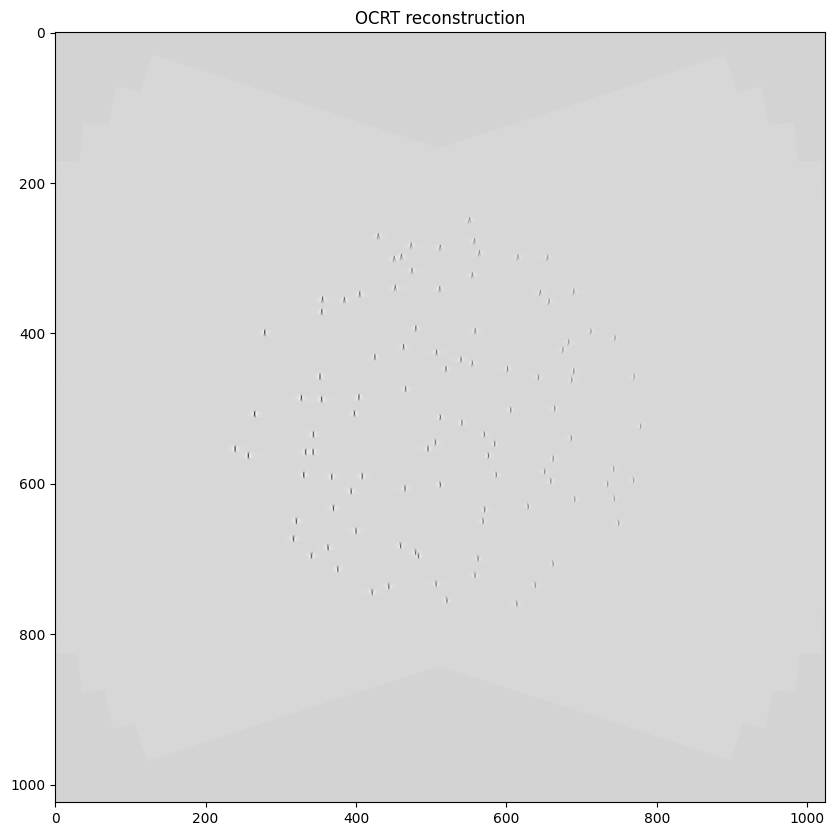

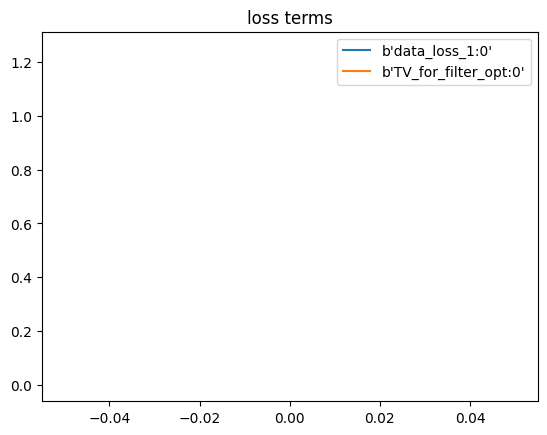

1 [1.2486397, 0.00084220176] 22.699901819229126


KeyboardInterrupt: 

In [ ]:
losses = list()
feed_dict = a.get_feed_dict()
for i in range(num_iter + 1):
    start = time()
    loss_i, _ = a.sess.run([a.loss_terms, a.train_op], feed_dict=feed_dict)
    losses.append(loss_i)
    print(i, loss_i, time()-start)
    
    # monitor results periodically:
    if i % 20 == 0:
        recon_i = a.sess.run(a.recon, feed_dict=feed_dict)
        recon_i = recon_i.sum(2)
        plt.figure(figsize=(10, 10))
        plt.imshow(recon_i, cmap='gray_r')
        plt.title('OCRT reconstruction')
        plt.show()
        
        plt.plot(losses)
        plt.legend(a.loss_term_names.eval())
        plt.title('loss terms')
        plt.show()

In [ ]:
a.save_graph()  # this graph doesn't need to be saved